# Task 80: API Latency and Inference Profiling

Profile model artifact loading and request pipeline stages, compare FP32/FP16/INT8 probability error and speed, and measure Python-traced memory.

Quantization comparison:


,weight bytes,500-row inference ms,mean absolute probability error,maximum error
mode,,,,
FP32,52,0.126098,0.000000,0.000000
FP16,26,0.242144,0.000063,0.000315
INT8,13,0.180717,0.001972,0.008781


,median ms,p95 ms,p99 ms
validation,0.05763,0.08907,0.11671
scaling,0.01457,0.02576,0.04652
inference,0.04731,0.08508,0.15341
explanation,0.03390,0.06871,0.13299
serialization,0.02713,0.04668,0.08531
total,0.18532,0.29976,0.50470


Artifact load: cold ms 8.1249 uncached disk load mean ms 0.7113 cached access us 1.0638
Peak traced allocation for 500 prediction calls (MiB): 0.0267


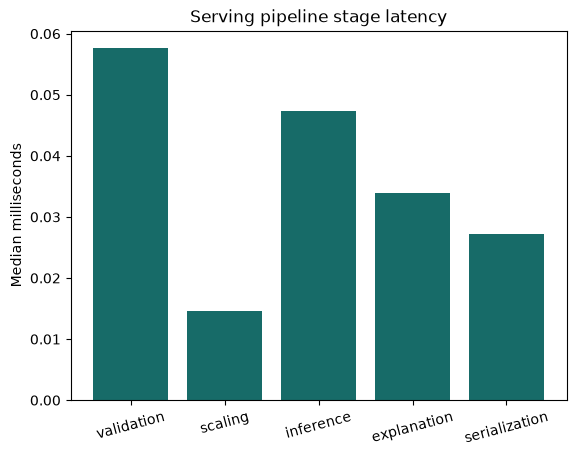

Only immutable model state is cached. User feature payloads are not cached because they are sensitive; quantization requires representative-data accuracy checks.


In [2]:
from pathlib import Path
from functools import lru_cache
import json
import time
import tracemalloc
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd().resolve()
artifact_candidates = [Path('Task_47_Versioned_Model_Export/artifacts/heart_logistic_v1.0.0.joblib'), Path('../Task_47_Versioned_Model_Export/artifacts/heart_logistic_v1.0.0.joblib')]
artifact_path = next(path for path in artifact_candidates if path.is_file())
data_paths = [Path('heart.csv'), Path('Task_80_API_Latency_Profiling/heart.csv'), Path('../Task_80_API_Latency_Profiling/heart.csv')]
data = pd.read_csv(next(path for path in data_paths if path.is_file())).drop_duplicates().reset_index(drop=True)


def stratified_split(x, labels, fraction=.2, seed=80):
    rng = np.random.default_rng(seed)
    train_parts, test_parts = [], []
    for label in np.unique(labels):
        indices = np.flatnonzero(labels == label)
        rng.shuffle(indices)
        cut = int(round(len(indices) * (1 - fraction)))
        train_parts.append(indices[:cut]); test_parts.append(indices[cut:])
    train, test = np.concatenate(train_parts), np.concatenate(test_parts)
    rng.shuffle(train); rng.shuffle(test)
    return x[train], x[test], labels[train], labels[test]


def validate_row(values, names):
    codes = {'sex': [0, 1], 'cp': [0, 1, 2, 3], 'fbs': [0, 1], 'restecg': [0, 1, 2], 'exang': [0, 1], 'slope': [0, 1, 2], 'ca': [0, 1, 2, 3, 4], 'thal': [0, 1, 2, 3]}
    bounds = {'age': (18, 100), 'trestbps': (60, 260), 'chol': (80, 700), 'thalach': (40, 250), 'oldpeak': (-5, 15)}
    parsed = {name: float(values[name]) for name in names}
    for name, value in parsed.items():
        if not np.isfinite(value):
            raise ValueError(f'{name} must be finite')
        if name in codes and (not value.is_integer() or int(value) not in codes[name]):
            raise ValueError(f'{name} must be an observed integer category code')
        if name in bounds and not bounds[name][0] <= value <= bounds[name][1]:
            raise ValueError(f'{name} is outside the configured input range')
    return parsed


@lru_cache(maxsize=1)
def load_artifact(path, modified_time):
    return joblib.load(path)


artifact_stat = artifact_path.stat()
start = time.perf_counter_ns()
artifact = load_artifact(str(artifact_path), artifact_stat.st_mtime_ns)
cold_load_ms = (time.perf_counter_ns() - start) / 1e6
start = time.perf_counter_ns()
for _ in range(20):
    joblib.load(artifact_path)
uncached_load_ms = (time.perf_counter_ns() - start) / 20e6
start = time.perf_counter_ns()
for _ in range(5000):
    load_artifact(str(artifact_path), artifact_stat.st_mtime_ns)
cached_access_us = (time.perf_counter_ns() - start) / 5000e3

features = artifact['feature_names']
means = np.asarray(artifact['preprocessing']['means'], dtype=np.float32)
scales = np.asarray(artifact['preprocessing']['scales'], dtype=np.float32)
weights = np.asarray(artifact['state']['weights'], dtype=np.float32)
bias = np.float32(artifact['state']['bias'])
frame = data[features]
example = {name: float(frame.iloc[0][name]) for name in features}
X = frame.to_numpy(dtype=np.float32)
y = data['target'].to_numpy(dtype=int)
X_train, X_test, y_train, y_test = stratified_split(X, y)


def sigmoid(value):
    return 1 / (1 + np.exp(-np.clip(value, -35, 35)))


def predict_fp32(x):
    return sigmoid(x @ weights + bias)


weights_fp16, bias_fp16 = weights.astype(np.float16), np.float16(bias)


def predict_fp16(x):
    logits = (x.astype(np.float16) @ weights_fp16).astype(np.float32) + np.float32(bias_fp16)
    return sigmoid(logits)


weight_scale = max(float(np.max(np.abs(weights))) / 127, 1e-12)
weights_int8 = np.clip(np.round(weights / weight_scale), -127, 127).astype(np.int8)
input_scale = 1 / 32


def predict_int8(x):
    quantized = np.clip(np.round(x / input_scale), -127, 127).astype(np.int8)
    logits = (quantized.astype(np.int32) @ weights_int8.astype(np.int32)) * input_scale * weight_scale + bias
    return sigmoid(logits)


rng = np.random.default_rng(80)
probes = rng.normal(size=(500, len(features))).astype(np.float32)
quantization_results = []
for name, function, size_bytes in [('FP32', predict_fp32, weights.nbytes), ('FP16', predict_fp16, weights_fp16.nbytes), ('INT8', predict_int8, weights_int8.nbytes)]:
    start = time.perf_counter_ns()
    scores = function(probes)
    elapsed_ms = (time.perf_counter_ns() - start) / 1e6
    reference = predict_fp32(probes)
    quantization_results.append({'mode': name, 'weight bytes': size_bytes, '500-row inference ms': elapsed_ms, 'mean absolute probability error': float(np.mean(np.abs(scores - reference))), 'maximum error': float(np.max(np.abs(scores - reference)))})
print('Quantization comparison:')
display(pd.DataFrame(quantization_results).set_index('mode').round(6))

# Time each serving stage on one valid row; model state stays in-process.
parsed_example = validate_row(example, features)
stage_runs = []
for _ in range(1500):
    timing = {}
    start = time.perf_counter_ns(); parsed = validate_row(example, features); timing['validation'] = (time.perf_counter_ns() - start) / 1e6
    start = time.perf_counter_ns(); scaled = (np.array([parsed[name] for name in features], dtype=np.float32) - means) / scales; timing['scaling'] = (time.perf_counter_ns() - start) / 1e6
    start = time.perf_counter_ns(); probability = float(predict_fp32(scaled[None, :])[0]); timing['inference'] = (time.perf_counter_ns() - start) / 1e6
    start = time.perf_counter_ns(); contributions = weights * scaled; top = np.argsort(np.abs(contributions))[::-1][:3]; explanation = [{'feature': features[index], 'contribution': float(contributions[index])} for index in top]; timing['explanation'] = (time.perf_counter_ns() - start) / 1e6
    start = time.perf_counter_ns(); json.dumps({'probability': probability, 'explanation': explanation}); timing['serialization'] = (time.perf_counter_ns() - start) / 1e6
    timing['total'] = sum(timing.values()); stage_runs.append(timing)

tracemalloc.start()
for _ in range(500):
    predict_fp32(np.array([[example[name] for name in features]], dtype=np.float32))
_, peak_memory = tracemalloc.get_traced_memory()
tracemalloc.stop()
stage_frame = pd.DataFrame(stage_runs)
display(pd.DataFrame({'median ms': stage_frame.median(), 'p95 ms': stage_frame.quantile(.95), 'p99 ms': stage_frame.quantile(.99)}).round(5))
print('Artifact load: cold ms', round(cold_load_ms, 4), 'uncached disk load mean ms', round(uncached_load_ms, 4), 'cached access us', round(cached_access_us, 4))
print('Peak traced allocation for 500 prediction calls (MiB):', round(peak_memory / 1024 ** 2, 4))
columns = [name for name in stage_frame.columns if name != 'total']
plt.bar(columns, [stage_frame[name].median() for name in columns], color='#176b68')
plt.ylabel('Median milliseconds'); plt.title('Serving pipeline stage latency'); plt.xticks(rotation=15); plt.show()
print('Only immutable model state is cached. User feature payloads are not cached because they are sensitive; quantization requires representative-data accuracy checks.')